### Assignment Description

In this project you will explore a dataset of your choice, including finding a meaningful target variable, finding suitable explanatory variables, and investigating the suitability of logistic regression or SVMs to them.

Your dataset should be suitable for logistic regression and SVMs. That is, they should have at least one variable that could be a target categorical variable. The remaining variables you will consider for explanatory variables can be categorical or quantitative, but your analysis might be a little easier if you choose quantitative variables. The target variable must have at least two classes, but be careful that it doesn't have too many classes or your predictive and runtime performance might suffer. Questions you should address in your report include the following:

- Which variables are predictive of the target variable?
- Can logistic regression or a linear SVM predict well?
- What do plots of selected pairs of variables look like? Where is the decision boundary in those plots?
- How generalizable are the different models on your data? How does the bias-variance tradeoff affect which model you might choose?
- Is there a difference between the polynomial and RBF SVMs?
- What effect does changing the class_weight in an SVM have on your data? How might this be important for this data?
- Is there a difference in runtime performance?
- Logistic regression and LinearSVC use one-vs-rest (OVR) for multi-class classification. SVC uses one-vs-one (OVO). Where n is the number of classes, OVR learns n models, whereas OVO learns n(n-1)/2 (n choose 2) models. What effect does this have on performance?

### Dataset

CTU-IDSEVAL-6: A Labeled Network Dataset for the Evaluation of Intrusion Detection Systems (Garcia et al.)
https://zenodo.org/records/21027042

## Binary traffic classification

This baseline maps the original `Benign` label to `legitimate`; all other labels (including malware and port scans) become `malicious`. Connection IDs and IP addresses are excluded because they are overly specific to these captures. A reproducible stratified sample keeps the nonlinear SVM grid search practical.

`LinearRegression` is included as requested, although it produces continuous values rather than class probabilities. Its predictions are clipped to [0, 1] for ROC-AUC and thresholded at 0.5 for class metrics.

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 5830
SAMPLE_SIZE = 18000  # makes the non-linear SVM search reasonable on a laptop

Loaded 286,702 connections from 6 files.


,connections
binary label,
legitimate,78742
malicious,207960


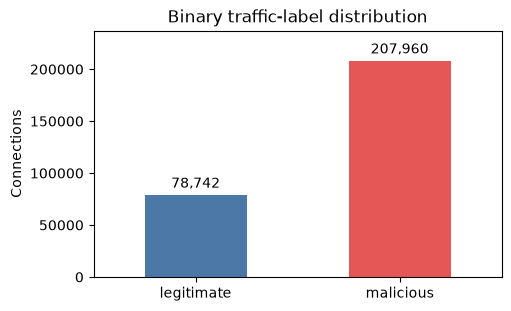

connections
label      detailedlabel             
Malicious  From_Malware        133353
Benign     Multicast            75305
Background NaN                  33163
Malicious  NaN                  33118
           CC                    8320
Benign     NaN                   3227
           Windows                210
Malicious  DNS                      6

In [2]:
def read_zeek_connection_log(path):
    """Read a tab-separated Zeek conn log whose header begins with #fields."""
    with open(path, encoding='utf-8') as handle:
        for line in handle:
            if line.startswith('#fields'):
                columns = line.rstrip('\n').split('\t')[1:]
                break
        else:
            raise ValueError(f'No #fields header found in {path}')
    return pd.read_csv(path, sep='\t', comment='#', header=None, names=columns,
                       na_values=['-', '(empty)'], low_memory=False)

log_paths = sorted(Path('data').glob('*.conn-labeled.log'))
traffic = pd.concat([read_zeek_connection_log(path) for path in log_paths], ignore_index=True)
traffic['target'] = np.where(traffic['label'].eq('Benign'), 'legitimate', 'malicious')

print(f'Loaded {len(traffic):,} connections from {len(log_paths)} files.')
label_counts = traffic['target'].value_counts().reindex(['legitimate', 'malicious'])
display(label_counts.rename_axis('binary label').to_frame('connections'))
fig, ax = plt.subplots(figsize=(5, 3), layout='constrained')
label_counts.plot.bar(ax=ax, color=['#4C78A8', '#E45756'], rot=0)
ax.set(title='Binary traffic-label distribution', xlabel='', ylabel='Connections')
ax.set_ylim(0, label_counts.max() * 1.14)  # reserve room for labels above the bars
ax.bar_label(ax.containers[0], labels=[f'{count:,}' for count in label_counts], padding=3)
plt.show()
display(traffic[['label', 'detailedlabel']].value_counts(dropna=False).rename('connections').to_frame())

In [3]:
# Broadly useful flow features; exclude uid, IP addresses, raw timestamps, and source labels.
numeric_features = ['id.orig_p', 'id.resp_p', 'duration', 'orig_bytes', 'resp_bytes',
                    'missed_bytes', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes']
categorical_features = ['proto', 'service', 'conn_state', 'history']

model_data = traffic[numeric_features + categorical_features + ['ts', 'target']].copy()
event_time = pd.to_datetime(model_data.pop('ts'), unit='s', utc=True)
model_data['hour_utc'] = event_time.dt.hour
model_data['weekday_utc'] = event_time.dt.dayofweek
numeric_features += ['hour_utc', 'weekday_utc']

# Log-transform the long-tailed traffic counts and byte measurements.
log_features = ['duration', 'orig_bytes', 'resp_bytes', 'missed_bytes', 'orig_pkts',
                'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes']
for column in log_features:
    model_data[column] = np.log1p(pd.to_numeric(model_data[column], errors='coerce').clip(lower=0))

sampled_data, _ = train_test_split(model_data, train_size=SAMPLE_SIZE,
                                    stratify=model_data['target'], random_state=RANDOM_STATE)
X = sampled_data.drop(columns='target')
y = sampled_data['target'].eq('malicious').astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric_features),
    ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                              ('one_hot', OneHotEncoder(handle_unknown='ignore'))]), categorical_features),
])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
print(f'Modeling sample: {len(X):,} connections ({y.mean():.1%} malicious); test set: {len(X_test):,}.')

Modeling sample: 18,000 connections (72.5% malicious); test set: 4,500.


Linear Regression best CV ROC-AUC: 0.9321
Best parameters: {'model__fit_intercept': False, 'model__tol': 0.0001}
Grid-search time: 2.5 seconds

Linear Regression
Hold-out prediction time: 0.0057 seconds (1.3 microseconds/connection)
Test ROC-AUC:  0.9276
Test accuracy: 0.8920
Confusion matrix [[TN, FP], [FN, TP]]:
[[1222   14]
 [ 472 2792]]


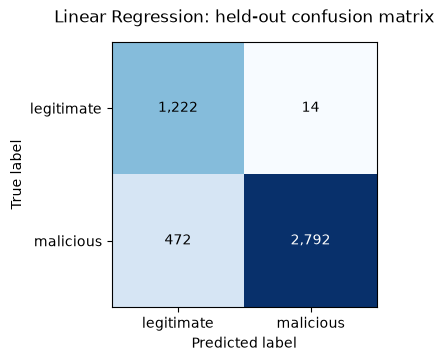

              precision    recall  f1-score   support

  legitimate      0.721     0.989     0.834      1236
   malicious      0.995     0.855     0.920      3264

    accuracy                          0.892      4500
   macro avg      0.858     0.922     0.877      4500
weighted avg      0.920     0.892     0.896      4500



In [4]:
def predict_scores(estimator, X):
    if hasattr(estimator, 'predict_proba'):
        return estimator.predict_proba(X)[:, 1]
    if hasattr(estimator, 'decision_function'):
        return estimator.decision_function(X)
    return estimator.predict(X)

def regression_roc_auc(estimator, X, y):
    return roc_auc_score(y, estimator.predict(X))

def evaluate_binary_model(name, estimator, X_test, y_test):
    prediction_start = time.perf_counter()
    raw_prediction = estimator.predict(X_test)
    prediction_seconds = time.perf_counter() - prediction_start
    scores = predict_scores(estimator, X_test)
    predicted = raw_prediction if hasattr(estimator, 'decision_function') else (scores >= 0.5).astype(int)
    print(f'\n{name}')
    print(f'Hold-out prediction time: {prediction_seconds:.4f} seconds '
          f'({prediction_seconds / len(X_test) * 1e6:.1f} microseconds/connection)')
    print(f'Test ROC-AUC:  {roc_auc_score(y_test, scores):.4f}')
    print(f'Test accuracy: {accuracy_score(y_test, predicted):.4f}')
    matrix = confusion_matrix(y_test, predicted)
    print('Confusion matrix [[TN, FP], [FN, TP]]:')
    print(matrix)
    fig, ax = plt.subplots(figsize=(4, 3.5), layout='constrained')
    image = ax.imshow(matrix, cmap='Blues')
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['legitimate', 'malicious'],
           yticklabels=['legitimate', 'malicious'], xlabel='Predicted label', ylabel='True label')
    ax.set_title(f'{name}: held-out confusion matrix', pad=14)
    for row in range(2):
        for column in range(2):
            ax.text(column, row, f'{matrix[row, column]:,}', ha='center', va='center',
                    color='white' if matrix[row, column] > matrix.max() / 2 else 'black')
    plt.show()
    print(classification_report(y_test, predicted, target_names=['legitimate', 'malicious'], digits=3))
    return {'model': name, 'test_roc_auc': roc_auc_score(y_test, scores),
            'test_accuracy': accuracy_score(y_test, predicted),
            'holdout_predict_seconds': prediction_seconds}

linear_grid = GridSearchCV(
    Pipeline([('preprocess', preprocessor), ('model', LinearRegression())]),
    param_grid={'model__fit_intercept': [True, False], 'model__tol': [1e-4, 1e-6]},
    scoring=regression_roc_auc, cv=cv, n_jobs=-1, refit=True, return_train_score=False
)
start = time.perf_counter()
linear_grid.fit(X_train, y_train)
linear_seconds = time.perf_counter() - start
print('Linear Regression best CV ROC-AUC:', round(linear_grid.best_score_, 4))
print('Best parameters:', linear_grid.best_params_)
print(f'Grid-search time: {linear_seconds:.1f} seconds')
linear_result = evaluate_binary_model('Linear Regression', linear_grid, X_test, y_test)

SVM best CV ROC-AUC: 0.9859
Best parameters: {'model__C': 1.0, 'model__class_weight': None, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Grid-search time: 12.4 seconds

SVM
Hold-out prediction time: 0.7722 seconds (171.6 microseconds/connection)
Test ROC-AUC:  0.9868
Test accuracy: 0.9529
Confusion matrix [[TN, FP], [FN, TP]]:
[[1031  205]
 [   7 3257]]


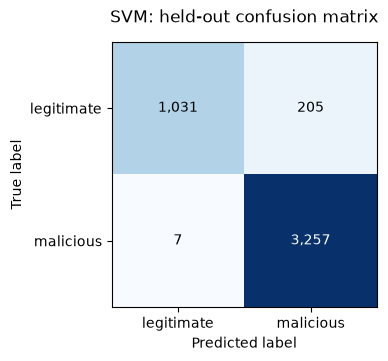

              precision    recall  f1-score   support

  legitimate      0.993     0.834     0.907      1236
   malicious      0.941     0.998     0.968      3264

    accuracy                          0.953      4500
   macro avg      0.967     0.916     0.938      4500
weighted avg      0.955     0.953     0.952      4500



,test_roc_auc,test_accuracy,holdout_predict_seconds
model,,,
Linear Regression,0.927560,0.892000,0.005707
SVM,0.986845,0.952889,0.772156


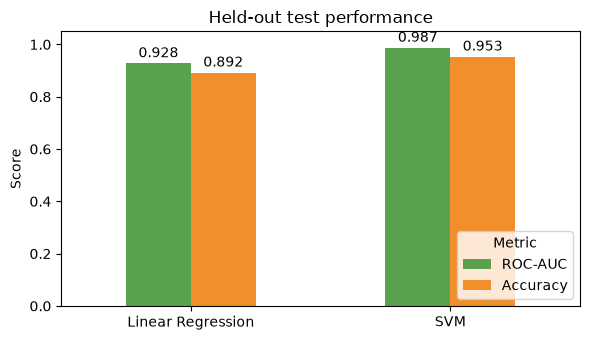

In [5]:
svm_grid = GridSearchCV(
    Pipeline([('preprocess', preprocessor), ('model', SVC(cache_size=1000))]),
    param_grid=[
        {'model__kernel': ['linear'], 'model__C': [0.3, 1.0],
         'model__class_weight': [None, 'balanced']},
        {'model__kernel': ['rbf'], 'model__C': [0.3, 1.0], 'model__gamma': ['scale', 0.1],
         'model__class_weight': [None, 'balanced']},
        {'model__kernel': ['poly'], 'model__C': [0.3, 1.0], 'model__degree': [2, 3],
         'model__gamma': ['scale'], 'model__class_weight': [None, 'balanced']},
    ],
    scoring='roc_auc', cv=cv, n_jobs=-1, refit=True, return_train_score=False
)
start = time.perf_counter()
svm_grid.fit(X_train, y_train)
svm_seconds = time.perf_counter() - start
print('SVM best CV ROC-AUC:', round(svm_grid.best_score_, 4))
print('Best parameters:', svm_grid.best_params_)
print(f'Grid-search time: {svm_seconds:.1f} seconds')
svm_result = evaluate_binary_model('SVM', svm_grid, X_test, y_test)

results = pd.DataFrame([linear_result, svm_result]).set_index('model')
display(results)
ax = results[['test_roc_auc', 'test_accuracy']].plot.bar(figsize=(6, 3.5), rot=0, ylim=(0, 1.05),
                                                        color=['#59A14F', '#F28E2B'])
ax.set(title='Held-out test performance', xlabel='', ylabel='Score')
ax.legend(['ROC-AUC', 'Accuracy'], title='Metric', loc='lower right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=2)
plt.tight_layout()
plt.show()

In [6]:
def show_grid_details(search, name):
    """Display each hyperparameter setting with its 3-fold CV score and timing."""
    raw = pd.DataFrame(search.cv_results_)
    parameter_columns = [column for column in raw if column.startswith('param_')]
    details = raw[parameter_columns + ['rank_test_score', 'mean_test_score', 'std_test_score',
                                      'mean_fit_time', 'std_fit_time']].copy()
    details.columns = [column.removeprefix('param_model__') for column in parameter_columns] + [
        'cv_rank', 'mean_cv_roc_auc', 'std_cv_roc_auc', 'mean_fit_seconds', 'std_fit_seconds'
    ]
    details = details.sort_values(['cv_rank', 'mean_fit_seconds']).reset_index(drop=True)
    print(f'\n{name}: all grid-search candidates (3-fold CV)')
    display(details.style.format({
        'mean_cv_roc_auc': '{:.4f}', 'std_cv_roc_auc': '{:.4f}',
        'mean_fit_seconds': '{:.3f}', 'std_fit_seconds': '{:.3f}'
    }))
    return details

linear_cv_details = show_grid_details(linear_grid, 'Linear Regression')
svm_cv_details = show_grid_details(svm_grid, 'SVM')

best_svm = svm_grid.best_estimator_.named_steps['model']
support_vector_counts = pd.DataFrame({
    'class': ['legitimate (0)', 'malicious (1)', 'total'],
    'support_vectors': [*best_svm.n_support_, best_svm.n_support_.sum()]
})
print('\nSupport vectors in the best refit SVM:')
display(support_vector_counts)
print('Selected SVM parameters:', svm_grid.best_params_)

# The tables above are deliberately retained as the detailed hyperparameter comparison.


Linear Regression: all grid-search candidates (3-fold CV)


,fit_intercept,tol,cv_rank,mean_cv_roc_auc,std_cv_roc_auc,mean_fit_seconds,std_fit_seconds
0,False,0.000001,1,0.9321,0.0012,0.036,0.003
1,False,0.000100,1,0.9321,0.0012,0.047,0.013
2,True,0.000001,3,0.9321,0.0011,0.049,0.013
3,True,0.000100,3,0.9321,0.0011,0.058,0.011



SVM: all grid-search candidates (3-fold CV)


,C,class_weight,kernel,gamma,degree,cv_rank,mean_cv_roc_auc,std_cv_roc_auc,mean_fit_seconds,std_fit_seconds
0,1.000000,nan,rbf,scale,nan,1,0.9859,0.0010,1.151,0.015
1,1.000000,nan,rbf,0.100000,nan,2,0.9854,0.0014,1.160,0.092
2,1.000000,nan,poly,scale,2.000000,3,0.9851,0.0006,0.959,0.020
3,0.300000,nan,poly,scale,2.000000,4,0.9842,0.0003,1.020,0.061
4,0.300000,nan,rbf,scale,nan,5,0.9842,0.0017,1.116,0.092
5,1.000000,balanced,poly,scale,2.000000,6,0.9840,0.0009,0.688,0.075
6,0.300000,nan,rbf,0.100000,nan,7,0.9838,0.0022,1.155,0.139
7,1.000000,nan,poly,scale,3.000000,8,0.9832,0.0022,0.846,0.215
8,0.300000,nan,poly,scale,3.000000,9,0.9831,0.0010,1.212,0.148
9,0.300000,balanced,poly,scale,2.000000,10,0.9830,0.0007,0.918,0.034



Support vectors in the best refit SVM:


,class,support_vectors
0,legitimate (0),1318
1,malicious (1),1302
2,total,2620


Selected SVM parameters: {'model__C': 1.0, 'model__class_weight': None, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
